# UrbanIQ: quem chega até a Prefeitura? Análise de dados da zeladoria urbana de São Paulo

**Global Solution 2026.2 | CitizenTech | Parte 3: Entrega técnica (Análise de Dados com Python)**

| Campo | Valor |
|---|---|
| Turma | 1TSCOB |
| Projeto | UrbanIQ |
| Equipe | DataGuy |
| Integrante (responsável) | Thiago Fiel de Oliveira, RM 570088 |

---

## 1. Identificação, problema e hipóteses

**Problema.** Buracos no asfalto, entulho em ponto viciado, árvore com risco de queda e boca de lobo entupida são problemas que afetam o dia a dia de quem mora em São Paulo. A Prefeitura recebe esses pedidos pelo **SP156** (telefone 156, portal, aplicativo e WhatsApp). O UrbanIQ, a CitizenTech que proponho no pitch, organiza esse fluxo: recebe o chamado, calcula um **score de prioridade** e mostra o andamento ao cidadão em um portal de transparência.

**Território.** Município de São Paulo, analisado pelas suas 32 subprefeituras.

Antes de desenhar a solução, eu queria entender com dados reais onde a zeladoria falha. Levantei três hipóteses na 1ª parte:

| Hipótese | Enunciado |
|---|---|
| **H1** | Os chamados de zeladoria demoram mais para ser finalizados nas subprefeituras periféricas do que nas centrais. |
| **H2** | A periferia registra **menos chamados por habitante**, o que indica subnotificação (o problema existe, mas não chega à Prefeitura). |
| **H3** | Os moradores da periferia dependem mais de canais não digitais (telefone 156), e poucos tipos de serviço concentram a maior parte da demanda. |

**Perguntas que a análise responde**

1. Qual o tamanho da demanda de zeladoria, e como ela evolui mês a mês?
2. Onde ela é mais crítica, e quais serviços concentram os pedidos?
3. O tempo de atendimento é diferente entre centro e periferia? (H1)
4. A quantidade de pedidos por habitante muda conforme a distância do centro? (H2)
5. O canal usado muda conforme o território? (H3)
6. Qual a probabilidade de um chamado ser resolvido em até 7 dias em cada território?

In [1]:
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})
# Paleta acessível (segura para daltonismo)
CORES = {'Central': '#1f77b4', 'Intermediário': '#ff7f0e', 'Periférico': '#2ca02c'}
ORDEM_ANEL = ['Central', 'Intermediário', 'Periférico']

# Caminhos relativos: o notebook roda a partir da pasta do ZIP
ARQ_T2 = 'dados/arquivo-final-2-trim-26.csv'
ARQ_T3 = 'dados/arquivo-final-3-trim-26.csv'
ARQ_POP = 'dados/populacao_subprefeituras_censo2022.csv'
print('Bibliotecas carregadas.')

Bibliotecas carregadas.


## 2. Fontes e descrição dos dados

Usei **duas bases públicas e reais**. Não usei nenhum dado simulado nesta análise.

| # | Base | Órgão responsável | Período | Link |
|---|---|---|---|---|
| 1 | Dados do SP156: Solicitações (2º e 3º trimestres de 2026) | SMIT, Secretaria Municipal de Inovação e Tecnologia (Prefeitura de São Paulo) | 01/04/2026 a 30/09/2026, extraído em 19/10/2026 | http://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156 |
| 2 | População por subprefeitura (Censo 2022) | IBGE, agregado pela Prefeitura de São Paulo (SMUL) | Censo Demográfico 2022 | https://prefeitura.sp.gov.br/web/se/w/município-de-são-paulo-subprefeituras-e-distritos-municipais |

A base 1 é publicada pela Prefeitura **já anonimizada**: não traz nome, CPF, telefone ou protocolo do cidadão. Ela tem uma linha por solicitação.

**Principais variáveis da base SP156** (conforme o dicionário oficial "SP156 2020 em diante"):

| Variável | Tipo | Descrição |
|---|---|---|
| `Data de Abertura` | data | Dia em que o cidadão abriu o pedido |
| `Data de Finalização` | data | Dia em que o protocolo foi fechado (vazio se ainda está aberto) |
| `Meio de Comunicação` | categoria | Canal: `PORTAL` (site), `CRM` (central telefônica 156), `MOBILE` (aplicativo), `CHATBOT` (WhatsApp), `INTEGRACAO`, `RESOLUCAO` |
| `Tema` / `Assunto` / `Serviço` | categoria | Classificação do pedido na Carta de Serviços, do mais geral ao mais específico |
| `Status` | categoria | `Finalizada`, `Aberto`, `Em Andamento`, `Cancelada` |
| `Órgão` | categoria | Órgão responsável pelo atendimento |
| `Latitude` / `Longitude` | número | Local do problema |
| `Prefeitura Operacional` | categoria | Subprefeitura do local |
| `Distrito` | categoria | Distrito do local |

**Variáveis da base de população:** `subprefeitura`, `pop_2010` e `pop_2022` (habitantes).

In [2]:
# Os dois trimestres vêm em formatos DIFERENTES (separador, codificação e formato de data).
# Por isso leio cada um com os parâmetros corretos, tudo como texto, para não perder informação.
t2 = pd.read_csv(ARQ_T2, sep=';', encoding='latin1', dtype=str)
t3 = pd.read_csv(ARQ_T3, sep=',', encoding='utf-8', dtype=str)
pop = pd.read_csv(ARQ_POP)

print(f'2º trimestre: {t2.shape[0]:,} linhas x {t2.shape[1]} colunas')
print(f'3º trimestre: {t3.shape[0]:,} linhas x {t3.shape[1]} colunas')
print(f'População: {pop.shape[0]} subprefeituras, total {pop.pop_2022.sum():,} habitantes')
print('Mesmas colunas nos dois trimestres?', list(t2.columns) == list(t3.columns))
t2.head(3)

2º trimestre: 463,686 linhas x 15 colunas
3º trimestre: 484,232 linhas x 15 colunas
População: 32 subprefeituras, total 11,451,999 habitantes
Mesmas colunas nos dois trimestres? True


,Data de Abertura,Data de Finalização,Meio de Comunicação,Tema,Assunto,Serviço,Status,Órgão,Logradouro,Número,CEP,Latitude,Longitude,Prefeitura Operacional,Distrito
0,01/04/2026,02/04/2026,CRM,Ouvidoria Geral do Município,Ouvidoria Geral do Município,Reclamação Anônima (Uso exclusivo da Ouvidoria),Finalizada,OGM - SMS,Rua Doutor Siqueira Campos,172,01509020,-23.5637222,-46.63729379999999,SE,LIBERDADE
1,01/04/2026,02/04/2026,PORTAL,Rua e bairro,Drenagem de água de chuva,Reformar galerias de águas de chuvas (pluviais),Finalizada,INTEGRAÇÃO-SMGI/SGZ,Rua dos Pinheiros,14,04966050,-23.7269671,-46.7809829,M BOI MIRIM,JARDIM ANGELA
2,01/04/2026,NaN,CRM,Rua e bairro,"Calçadas, guias e postes","Guias, sarjetas e sarjetões - solicitar manute...",Aberto,INTEGRAÇÃO-SMGI/SGZ,Avenida Líder,1732,08280005,-23.5563286,-46.478276,ITAQUERA,CIDADE LIDER


## 3. Limpeza e preparação dos dados

### 3.1 Estado inicial

Antes de qualquer tratamento, olho as primeiras datas de cada arquivo. O 2º trimestre usa o formato **dd/mm/aaaa** e o 3º usa **mm/dd/aaaa**: uma data `07/25/2026` só existe se o mês vier primeiro. Se eu lesse os dois com o mesmo formato, metade das datas ficaria trocada ou inválida.

In [3]:
print('Exemplos de datas do 2º trimestre:', t2['Data de Finalização'].dropna().head(3).tolist())
print('Exemplos de datas do 3º trimestre:', t3['Data de Finalização'].dropna().head(3).tolist())

estado_inicial = pd.concat([t2, t3], ignore_index=True)
print(f'\nTotal de linhas antes da limpeza: {len(estado_inicial):,}')
print('\n% de valores ausentes por coluna:')
print((estado_inicial.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

Exemplos de datas do 2º trimestre: ['02/04/2026', '02/04/2026', '02/04/2026']
Exemplos de datas do 3º trimestre: ['07/25/2026', '07/25/2026', '10/01/2026']



Total de linhas antes da limpeza: 947,918

% de valores ausentes por coluna:


Prefeitura Operacional   36.80
Distrito                 36.80
Latitude                 36.60
Número                   36.60
Logradouro               36.60
CEP                      36.60
Longitude                36.60
Data de Finalização      16.40
Serviço                   0.00
Status                    0.00
Tema                      0.00
Meio de Comunicação       0.00
Data de Abertura          0.00
Assunto                   0.00
Órgão                     0.00


**O que eu observei no estado inicial:**

- **Datas em formatos diferentes** entre os arquivos (dd/mm e mm/dd).
- **`Data de Finalização` vazia** em 14% a 19% das linhas. Isso **não é erro**: são chamados ainda abertos.
- **Localização vazia em cerca de 37% das linhas.** São serviços que não têm endereço (por exemplo, registro de animal ou certidão). Eles ficam fora do escopo de zeladoria de qualquer forma.
- Nomes de subprefeitura **fora do padrão**: `CASA VERDE-LIMAO-CACHOEIRINHA` e `CASA VERDE-CACHOEIRINHA` são a mesma subprefeitura, assim como `PERUS` e `PERUS-ANHANGUERA`. Também aparecem valores que **não são subprefeituras**, como `Superintendencia das Usinas de Asfalto` e `Prefeitura Regional nao encontrada`.

In [4]:
estado_inicial['Prefeitura Operacional'].value_counts().tail(12)

Prefeitura Operacional
ERMELINO MATARAZZO                                  9279
GUAIANASES                                          9244
SAPOPEMBA                                           8186
CIDADE TIRADENTES                                   6070
PARELHEIROS                                         5136
PERUS-ANHANGUERA                                    4441
Superintendencia das Usinas de Asfalto              2311
CASA VERDE-CACHOEIRINHA                             1075
Prefeitura Regional nao encontrada                   334
PERUS                                                310
Departamento de Estradas de Rodagem                   20
Secretaria Municipal do Verde e do Meio Ambiente       7
Name: count, dtype: int64

### 3.2 Tratamentos aplicados

| Passo | Tratamento | Justificativa |
|---|---|---|
| 1 | Converter as datas com o formato certo de cada arquivo | Evitar datas trocadas, que distorceriam todo o cálculo de tempo |
| 2 | Recortar o escopo para **zeladoria** (12 assuntos ligados ao espaço público) | É o problema que o UrbanIQ resolve. Temas como saúde ou finanças têm outra lógica de atendimento |
| 3 | Padronizar os nomes das subprefeituras e remover os valores que não são subprefeituras | Permitir a junção com a base de população e a comparação entre territórios |
| 4 | Remover duplicados exatos | A base não tem número de protocolo. Linhas idênticas (mesmo dia, serviço, endereço e status) representam o **mesmo problema** relatado mais de uma vez. Mantê-las daria peso dobrado a esses casos no cálculo de tempo. Guardo a contagem como "reiterações" |
| 5 | Criar `dias_atendimento` = finalização menos abertura, só para chamados `Finalizada` | Chamados abertos ainda não têm tempo final (ver limitações) |
| 6 | Calcular a distância de cada chamado até o Marco Zero (Praça da Sé) | Criar um critério **objetivo** de centro e periferia, em vez de uma lista escolhida à mão |
| 7 | Normalizar a demanda por **1.000 habitantes** | Subprefeituras têm populações muito diferentes (de 163 mil a 676 mil). Sem normalizar, a comparação de volume seria injusta |

In [5]:
# Passo 1: datas com o formato correto de cada arquivo
t2['dt_abertura'] = pd.to_datetime(t2['Data de Abertura'], format='%d/%m/%Y')
t2['dt_finalizacao'] = pd.to_datetime(t2['Data de Finalização'], format='%d/%m/%Y', errors='coerce')
t3['dt_abertura'] = pd.to_datetime(t3['Data de Abertura'], format='%m/%d/%Y')
t3['dt_finalizacao'] = pd.to_datetime(t3['Data de Finalização'], format='%m/%d/%Y', errors='coerce')
t2['trimestre'], t3['trimestre'] = '2º TRI 2026', '3º TRI 2026'

df = pd.concat([t2, t3], ignore_index=True)
print('Período de abertura:', df.dt_abertura.min().date(), 'a', df.dt_abertura.max().date())
print('Datas de abertura inválidas:', df.dt_abertura.isna().sum())

# Passo 2: escopo de zeladoria (problemas físicos do espaço público)
ASSUNTOS_ZELADORIA = {
    'Reparos em  Asfalto, Pontes, Viadutos e Túneis': 'Asfalto e vias',
    'Ponto viciado, entulho e caçamba de entulho': 'Entulho e ponto viciado',
    'Árvore': 'Árvores',
    'Fiação e Postes': 'Fiação e postes',
    'Varrição e limpeza urbana': 'Varrição e limpeza',
    'Capinação e roçada de áreas verdes': 'Capinação e roçada',
    'Drenagem de água de chuva': 'Drenagem',
    'Lixeiras Públicas': 'Lixeiras públicas',
    'Calçadas, guias e postes': 'Calçadas e guias',
    'Remoção de grandes objetos': 'Grandes objetos',
    'Rios e Córregos': 'Rios e córregos',
    'Praças': 'Praças',
}
z = df[df['Assunto'].isin(ASSUNTOS_ZELADORIA)].copy()
z['servico'] = z['Assunto'].map(ASSUNTOS_ZELADORIA)
print(f'Chamados de zeladoria: {len(z):,} ({len(z)/len(df):.1%} da base)')

Período de abertura: 2026-04-01 a 2026-09-30
Datas de abertura inválidas: 0


Chamados de zeladoria: 259,009 (27.3% da base)


In [6]:
# Passo 3: padronização das subprefeituras
def normaliza(txt):
    """Remove acentos e apóstrofos e passa para maiúsculas, para casar nomes de bases diferentes."""
    return unicodedata.normalize('NFKD', str(txt)).encode('ascii', 'ignore').decode().upper().replace("'", '').strip()

SINONIMOS = {'CASA VERDE-LIMAO-CACHOEIRINHA': 'CASA VERDE-CACHOEIRINHA', 'PERUS-ANHANGUERA': 'PERUS'}
pop['sub'] = pop['subprefeitura'].map(normaliza)
z['sub'] = z['Prefeitura Operacional'].map(normaliza).replace(SINONIMOS)

antes = len(z)
z = z[z['sub'].isin(pop['sub'])].copy()
print(f'Removidas {antes - len(z):,} linhas sem subprefeitura válida (ausente ou órgão não territorial).')
print('Subprefeituras distintas após a padronização:', z['sub'].nunique())

# Passo 4: duplicados exatos = reiterações do mesmo problema
colunas_originais = list(t2.columns)
dup = z.duplicated(subset=colunas_originais)
reiteracoes = int(dup.sum())
z = z[~dup].copy()
print(f'Reiterações (duplicados exatos) removidas: {reiteracoes:,}')

# Status com volume irrelevante
print(z['Status'].value_counts().to_string())

Removidas 2,609 linhas sem subprefeitura válida (ausente ou órgão não territorial).
Subprefeituras distintas após a padronização: 32


Reiterações (duplicados exatos) removidas: 11,245
Status
Finalizada      197615
Aberto           47003
Cancelada          422
Em Andamento       115


In [7]:
# Passo 5: tempo de atendimento
z['dias_atendimento'] = (z['dt_finalizacao'] - z['dt_abertura']).dt.days
inconsist = z['Status'].eq('Finalizada') & z['dias_atendimento'].isna()
print('Finalizadas sem data de finalização (inconsistência):', int(inconsist.sum()))
print('Tempos negativos (erro de data):', int((z['dias_atendimento'] < 0).sum()))
z = z[~inconsist].copy()  # removo as 3 linhas inconsistentes (status e data se contradizem)
z.loc[~z['Status'].eq('Finalizada'), 'dias_atendimento'] = np.nan

# Outliers pelo critério do IQR
fin = z[z['Status'].eq('Finalizada') & z['dias_atendimento'].notna()]
q1, q3 = fin['dias_atendimento'].quantile([.25, .75])
lim = q3 + 1.5 * (q3 - q1)
print(f'Limite superior IQR: {lim:.0f} dias | chamados acima: {(fin.dias_atendimento > lim).mean():.1%}')

Finalizadas sem data de finalização (inconsistência): 3
Tempos negativos (erro de data): 0


Limite superior IQR: 18 dias | chamados acima: 13.1%


**Decisão sobre outliers.** Cerca de 13% dos chamados finalizados passam do limite do IQR (mais de 18 dias). Eu **não removi** esses casos. Eles não são erro de digitação: são cidadãos que realmente esperaram semanas, e são exatamente os casos que o UrbanIQ quer evitar. Para lidar com a assimetria, uso a **mediana** nas comparações e um **teste não paramétrico** (Mann-Whitney) em vez do teste t.

In [8]:
# Passo 6: distância até o Marco Zero (fórmula de Haversine) e anel territorial
z['lat'] = pd.to_numeric(z['Latitude'], errors='coerce')
z['lon'] = pd.to_numeric(z['Longitude'], errors='coerce')

def haversine_km(lat, lon, lat0=-23.5503, lon0=-46.6339):
    """Distância em km entre cada ponto e o Marco Zero de São Paulo (Praça da Sé)."""
    lat, lon, lat0, lon0 = map(np.radians, [lat, lon, lat0, lon0])
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

z['km_marco_zero'] = haversine_km(z['lat'], z['lon'])

# Cada subprefeitura recebe a mediana da distância dos seus chamados.
# Divido as 32 subprefeituras em 3 grupos de tamanho parecido (tercis).
dist_sub = z.groupby('sub')['km_marco_zero'].median().sort_values()
anel = pd.qcut(dist_sub, 3, labels=ORDEM_ANEL)
z['anel'] = z['sub'].map(anel).astype(str)

for nome in ORDEM_ANEL:
    print(f'{nome:13s}:', ', '.join(anel[anel == nome].index.str.title()))

Central      : Se, Mooca, Vila Mariana, Pinheiros, Lapa, Ipiranga, Santana-Tucuruvi, Vila Maria-Vila Guilherme, Casa Verde-Cachoeirinha, Vila Prudente, Aricanduva-Formosa-Carrao
Intermediário: Freguesia-Brasilandia, Jabaquara, Jacana-Tremembe, Butanta, Penha, Santo Amaro, Sapopemba, Pirituba-Jaragua, Cidade Ademar, Ermelino Matarazzo
Periférico   : Itaquera, Campo Limpo, Sao Mateus, M Boi Mirim, Perus, Sao Miguel, Capela Do Socorro, Guaianases, Cidade Tiradentes, Itaim Paulista, Parelheiros


In [9]:
# Passo 7 (integração + normalização): chamados por 1.000 habitantes
ind = (z.groupby('sub').agg(chamados=('servico', 'size'),
                            mediana_dias=('dias_atendimento', 'median'),
                            media_dias=('dias_atendimento', 'mean'),
                            pct_aberto=('Status', lambda s: (s == 'Aberto').mean()),
                            pct_telefone=('Meio de Comunicação', lambda s: (s == 'CRM').mean()))
         .join(dist_sub.rename('km_mediana'))
         .join(anel.rename('anel').astype(str))
         .reset_index()
         .merge(pop[['sub', 'subprefeitura', 'pop_2022']], on='sub', how='inner', validate='one_to_one'))
ind['chamados_mil_hab'] = ind['chamados'] / ind['pop_2022'] * 1000

# Normalização Min-Max (0 a 1) para criar um índice de subnotificação comparável
t = ind['chamados_mil_hab']
ind['indice_subnotificacao'] = 1 - (t - t.min()) / (t.max() - t.min())
print('Subprefeituras na junção:', len(ind), '| habitantes cobertos:', f"{ind.pop_2022.sum():,}")

# Resultado final da preparação
print(f'\nBase final de zeladoria: {len(z):,} chamados | {z["sub"].nunique()} subprefeituras | '
      f'{z["dt_abertura"].dt.to_period("M").nunique()} meses')
z[['dt_abertura', 'dt_finalizacao', 'Meio de Comunicação', 'servico', 'Status', 'sub', 'anel',
   'km_marco_zero', 'dias_atendimento']].head()

Subprefeituras na junção: 32 | habitantes cobertos: 11,451,999

Base final de zeladoria: 245,152 chamados | 32 subprefeituras | 6 meses


,dt_abertura,dt_finalizacao,Meio de Comunicação,servico,Status,sub,anel,km_marco_zero,dias_atendimento
1,2026-04-01,2026-04-02,PORTAL,Drenagem,Finalizada,M BOI MIRIM,Periférico,24.71,1.00
2,2026-04-01,NaT,CRM,Calçadas e guias,Aberto,ITAQUERA,Periférico,15.88,NaN
6,2026-04-01,2026-04-02,MOBILE,Asfalto e vias,Finalizada,SE,Central,0.27,1.00
30,2026-04-01,2026-04-14,CRM,Árvores,Finalizada,SAO MIGUEL,Periférico,17.42,13.00
32,2026-04-01,2026-04-14,CRM,Rios e córregos,Finalizada,ERMELINO MATARAZZO,Intermediário,16.37,13.00


In [10]:
# Exporto as bases tratadas (também usadas no painel do Power BI)
cols = ['dt_abertura', 'dt_finalizacao', 'trimestre', 'Meio de Comunicação', 'Tema', 'servico', 'Serviço',
        'Status', 'Órgão', 'sub', 'Distrito', 'anel', 'lat', 'lon', 'km_marco_zero', 'dias_atendimento']
z[cols].rename(columns={'Meio de Comunicação': 'canal', 'Serviço': 'servico_detalhe', 'Órgão': 'orgao',
                        'sub': 'subprefeitura', 'Distrito': 'distrito', 'Tema': 'tema', 'Status': 'status'}
               ).to_csv('dados/tratados_chamados_zeladoria.csv', index=False, encoding='utf-8')
ind.to_csv('dados/tratados_indicadores_subprefeitura.csv', index=False, encoding='utf-8')
print('Arquivos tratados salvos em dados/.')

Arquivos tratados salvos em dados/.


## 4. Análise exploratória e estatística descritiva

### 4.1 Tamanho do problema e evolução

In [11]:
finalizados = z[z['Status'].eq('Finalizada') & z['dias_atendimento'].notna()]
print(f'Chamados de zeladoria em 6 meses: {len(z):,}  (~{len(z)/183:,.0f} por dia)')
print(f'Reiterações do mesmo problema:     {reiteracoes:,}')
print(f'Finalizados: {len(finalizados)/len(z):.1%} | ainda abertos na extração: {(z.Status=="Aberto").mean():.1%}')
print('\nTempo de atendimento dos chamados finalizados (dias):')
desc = finalizados['dias_atendimento'].describe(percentiles=[.25, .5, .75, .9])
print(desc.round(2).to_string())
print(f"\nAssimetria: {finalizados['dias_atendimento'].skew():.2f} | "
      f"coeficiente de variação: {desc['std']/desc['mean']:.0%}")

Chamados de zeladoria em 6 meses: 245,152  (~1,340 por dia)
Reiterações do mesmo problema:     11,245
Finalizados: 80.6% | ainda abertos na extração: 19.2%

Tempo de atendimento dos chamados finalizados (dias):
count   197,612.00
mean          7.55
std          13.75
min           0.00
25%           1.00
50%           2.00
75%           8.00
90%          22.00
max         127.00

Assimetria: 3.29 | coeficiente de variação: 182%


**Leitura.** São quase **1.400 chamados de zeladoria por dia**. O tempo de atendimento é muito assimétrico: a **mediana é de 2 dias**, mas a média passa de 7 dias, puxada por uma cauda longa (10% dos casos demoram mais de 3 semanas). A dispersão é alta (coeficiente de variação acima de 180%). Por isso a média sozinha engana, e a mediana é a medida mais honesta para comparar grupos.

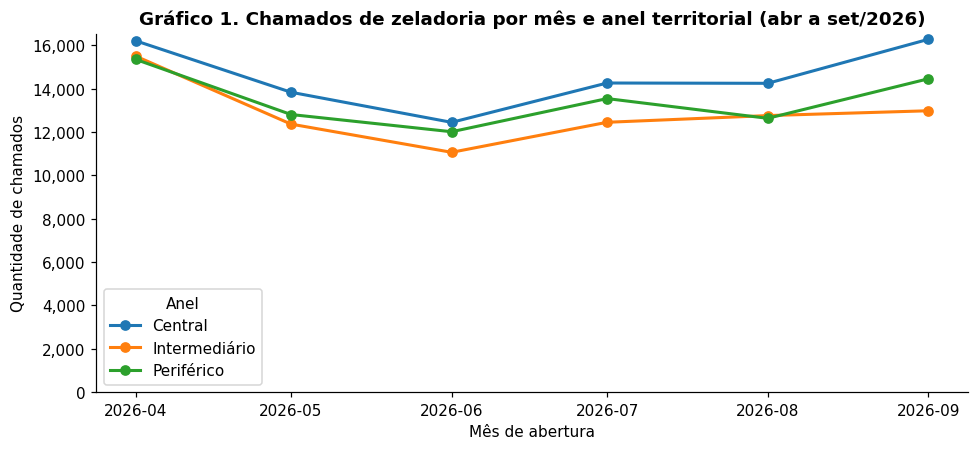

anel        Central  Intermediário  Periférico
mes                                           
2026-04-01    16207          15500       15349
2026-05-01    13832          12363       12805
2026-06-01    12444          11062       12011
2026-07-01    14258          12447       13540
2026-08-01    14244          12756       12630
2026-09-01    16273          12978       14453


In [12]:
# Gráfico 1: evolução mensal por anel
mensal = (z.assign(mes=z['dt_abertura'].dt.to_period('M').dt.to_timestamp())
            .groupby(['mes', 'anel']).size().unstack()[ORDEM_ANEL])
fig, ax = plt.subplots(figsize=(9, 4.2))
for a in ORDEM_ANEL:
    ax.plot(mensal.index, mensal[a], marker='o', lw=2, color=CORES[a], label=a)
ax.set_title('Gráfico 1. Chamados de zeladoria por mês e anel territorial (abr a set/2026)')
ax.set_xlabel('Mês de abertura')
ax.set_ylabel('Quantidade de chamados')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_ylim(0)
ax.legend(title='Anel')
plt.tight_layout(); plt.savefig('graficos/g1_evolucao_mensal.png', bbox_inches='tight'); plt.show()
print(mensal)

**Interpretação do Gráfico 1.** A demanda é estável ao longo dos seis meses, sem pico sazonal forte. Os três anéis têm **volumes absolutos parecidos**. Mas o anel periférico tem bem mais moradores (veja a seção 4.3). Então um volume igual já é o primeiro sinal de que a periferia pede proporcionalmente menos.

### 4.2 Onde se concentra a demanda (H3, parte de serviços)

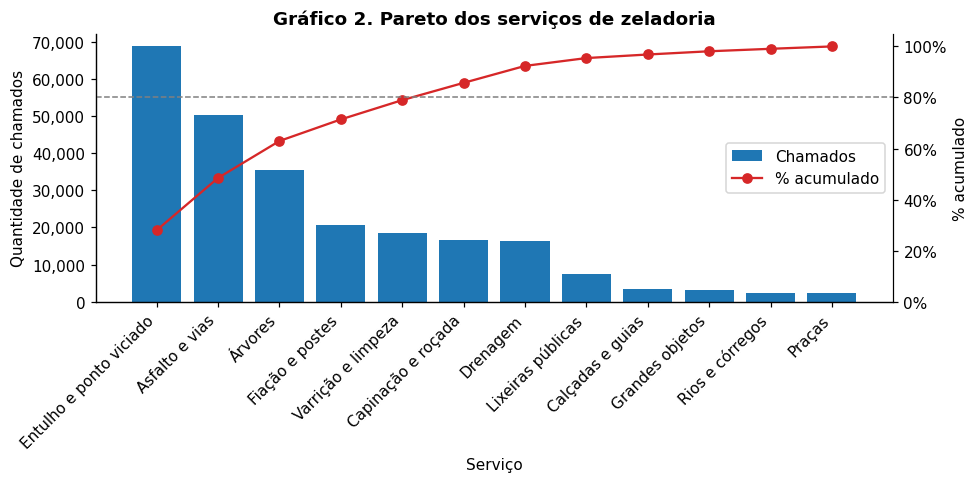

servico
Entulho e ponto viciado   28.00
Asfalto e vias            20.50
Árvores                   14.50
Fiação e postes            8.40
Varrição e limpeza         7.60
Capinação e roçada         6.80
Drenagem                   6.60
Lixeiras públicas          3.10
Calçadas e guias           1.40
Grandes objetos            1.30
Rios e córregos            1.00
Praças                     0.90


In [13]:
# Gráfico 2: Pareto dos serviços
cont = z['servico'].value_counts()
acum = cont.cumsum() / cont.sum() * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(cont.index, cont.values, color='#1f77b4', label='Chamados')
ax.set_ylabel('Quantidade de chamados')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.tick_params(axis='x', rotation=45)
plt.setp(ax.get_xticklabels(), ha='right')
ax2 = ax.twinx()
ax2.plot(cont.index, acum.values, color='#d62728', marker='o', label='% acumulado')
ax2.axhline(80, ls='--', color='gray', lw=1)
ax2.set_ylim(0, 105); ax2.set_ylabel('% acumulado')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.spines['right'].set_visible(True)
ax.set_title('Gráfico 2. Pareto dos serviços de zeladoria')
ax.set_xlabel('Serviço')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='center right')
plt.tight_layout(); plt.savefig('graficos/g2_pareto_servicos.png', bbox_inches='tight'); plt.show()
print((cont / cont.sum() * 100).round(1).to_string())

**Interpretação do Gráfico 2.** Os **três primeiros serviços** (asfalto, entulho e árvores) somam cerca de dois terços dos pedidos, e seis serviços passam de 80%. Isso confirma a parte de serviços da H3. Na prática, um score de priorização bem calibrado para poucas categorias já cobre a maior parte da operação.

### 4.3 Comparação entre territórios

In [14]:
comp = (z.groupby('anel')
          .agg(subprefeituras=('sub', 'nunique'), chamados=('servico', 'size'),
               mediana_dias=('dias_atendimento', 'median'), media_dias=('dias_atendimento', 'mean'),
               desvio_dias=('dias_atendimento', 'std'), pct_aberto=('Status', lambda s: (s == 'Aberto').mean()))
          .reindex(ORDEM_ANEL))
comp['habitantes'] = ind.groupby('anel')['pop_2022'].sum().reindex(ORDEM_ANEL)
comp['chamados_mil_hab'] = comp['chamados'] / comp['habitantes'] * 1000
comp

,subprefeituras,chamados,mediana_dias,media_dias,desvio_dias,pct_aberto,habitantes,chamados_mil_hab
anel,,,,,,,,
Central,11,87258,2.00,8.00,14.30,0.20,3654535,23.88
Intermediário,10,77106,2.00,7.63,13.92,0.19,3454925,22.32
Periférico,11,80788,2.00,7.00,12.96,0.18,4342539,18.60


In [15]:
# Ranking de subprefeituras por chamados por mil habitantes
ind.sort_values('chamados_mil_hab')[['subprefeitura', 'anel', 'pop_2022', 'chamados',
                                      'chamados_mil_hab', 'mediana_dias', 'pct_telefone']].head(8)

,subprefeitura,anel,pop_2022,chamados,chamados_mil_hab,mediana_dias,pct_telefone
6,Cidade Tiradentes,Periférico,194177,2441,12.57,1.00,0.27
20,Perus,Periférico,163083,2287,14.02,1.00,0.27
16,M Boi Mirim,Periférico,570809,8446,14.80,2.00,0.32
18,Parelheiros,Periférico,165138,2555,15.47,1.00,0.18
27,Sapopemba,Intermediário,266715,4229,15.86,2.00,0.28
9,Guaianases,Periférico,273707,4524,16.53,1.00,0.36
5,Cidade Ademar,Intermediário,412804,6993,16.94,2.00,0.31
25,São Mateus,Periférico,453527,7759,17.11,2.00,0.29


**Leitura.** O anel periférico tem **mais moradores**, mas registra **menos chamados por mil habitantes** do que o central. As 8 subprefeituras que menos pedem por habitante são quase todas periféricas (Cidade Tiradentes, Perus, M'Boi Mirim, Parelheiros, Guaianases e outras). Já o tempo mediano de atendimento é praticamente o mesmo nos três anéis. Os testes da seção 5 verificam se essas diferenças são estatisticamente relevantes.

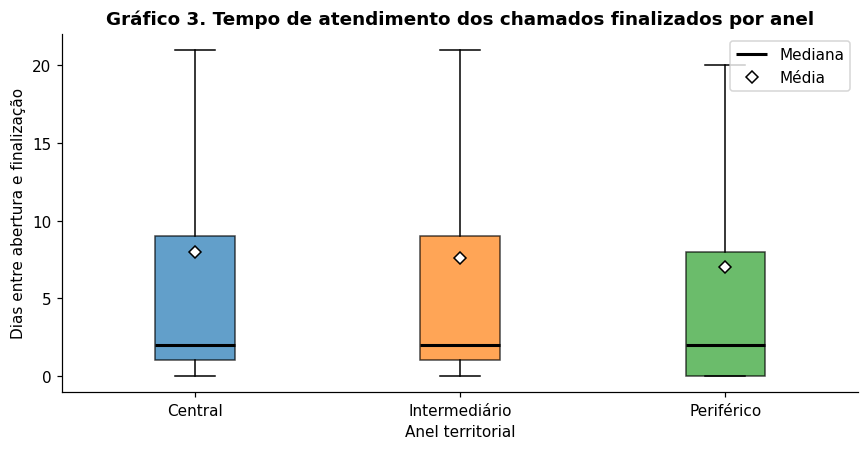

In [16]:
# Gráfico 3: distribuição do tempo de atendimento por anel (boxplot sem outliers, para legibilidade)
dados_box = [finalizados.loc[finalizados.anel == a, 'dias_atendimento'] for a in ORDEM_ANEL]
fig, ax = plt.subplots(figsize=(8, 4.2))
bp = ax.boxplot(dados_box, tick_labels=ORDEM_ANEL, showfliers=False, patch_artist=True, showmeans=True,
                meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black'),
                medianprops=dict(color='black', lw=2))
for patch, a in zip(bp['boxes'], ORDEM_ANEL):
    patch.set_facecolor(CORES[a]); patch.set_alpha(.7)
ax.set_title('Gráfico 3. Tempo de atendimento dos chamados finalizados por anel')
ax.set_xlabel('Anel territorial')
ax.set_ylabel('Dias entre abertura e finalização')
ax.legend([bp['medians'][0], bp['means'][0]], ['Mediana', 'Média'], loc='upper right')
plt.tight_layout(); plt.savefig('graficos/g3_tempo_por_anel.png', bbox_inches='tight'); plt.show()

**Interpretação do Gráfico 3.** As caixas são muito parecidas. A mediana fica em 1 a 2 dias nos três anéis, e a média do anel periférico é até um pouco **menor**. Visualmente, não há sinal de que a periferia espere mais.

## 5. Aplicação das técnicas escolhidas

Escolhi quatro técnicas. Cada uma responde a uma pergunta específica:

| Técnica | Pergunta que responde | Hipótese |
|---|---|---|
| 5.1 Integração de dados | Quantos pedidos existem **por habitante** em cada território? | H2 |
| 5.2 Testes de hipóteses | As diferenças de tempo e de canal entre centro e periferia são reais ou acaso? | H1 e H3 |
| 5.3 Correlação | A demanda por habitante cai conforme a distância do centro aumenta? | H2 |
| 5.4 Probabilidade | Qual a chance de o problema ser resolvido em até 7 dias em cada anel? | H1 |

### 5.1 Integração de dados (SP156 + Censo 2022)

**Por que escolhi.** O SP156 conta pedidos, mas não sabe quantas pessoas moram em cada lugar. Sem a população, uma subprefeitura grande sempre "pareceria" ter mais problemas. Ao integrar com o Censo, consigo uma taxa justa: **chamados por 1.000 habitantes**. A junção foi feita pelo nome normalizado da subprefeitura, com validação `one_to_one`. As 32 subprefeituras casaram, cobrindo os 11.451.999 habitantes do município.

In [17]:
r = ind.groupby('anel')['chamados_mil_hab'].agg(['median', 'min', 'max']).reindex(ORDEM_ANEL)
print(r.round(1))
mx, mn = ind.loc[ind.chamados_mil_hab.idxmax()], ind.loc[ind.chamados_mil_hab.idxmin()]
print(f"\nMaior taxa: {mx.subprefeitura} ({mx.chamados_mil_hab:.1f}/mil hab) | "
      f"Menor: {mn.subprefeitura} ({mn.chamados_mil_hab:.1f}/mil hab) | razão: {mx.chamados_mil_hab/mn.chamados_mil_hab:.1f}x")

               median   min   max
anel                             
Central         23.80 19.70 29.00
Intermediário   22.50 15.90 29.50
Periférico      17.10 12.60 25.80

Maior taxa: Jabaquara (29.5/mil hab) | Menor: Cidade Tiradentes (12.6/mil hab) | razão: 2.3x


**Resultado e interpretação.** A integração revela uma diferença de **mais de 2 vezes** entre a subprefeitura que mais pede e a que menos pede. Não é plausível que uma região periférica, com menos infraestrutura, tenha metade dos buracos, entulho ou árvores com problema. A explicação mais provável é que **o problema existe, mas não vira chamado**. Esse é o centro da H2.

### 5.2 Testes de hipóteses

**Por que escolhi.** Comparar médias "no olho" não basta, pois com centenas de milhares de linhas qualquer diferença pequena aparece. O teste diz se a diferença é estatisticamente significativa, e o tamanho do efeito diz se ela importa na prática.

**Teste A (H1): Mann-Whitney unilateral.** Escolhi esse teste porque o tempo de atendimento é muito assimétrico (seção 4.1), o que viola a normalidade exigida pelo teste t.

- H0: o tempo de atendimento na periferia **não é maior** que no centro.
- H1: o tempo de atendimento na periferia **é maior** que no centro.
- Nível de significância: α = 0,05.

In [18]:
per = finalizados.loc[finalizados.anel == 'Periférico', 'dias_atendimento']
cen = finalizados.loc[finalizados.anel == 'Central', 'dias_atendimento']
u, p_maior = stats.mannwhitneyu(per, cen, alternative='greater')
_, p_bi = stats.mannwhitneyu(per, cen, alternative='two-sided')
# Tamanho do efeito: probabilidade de superioridade (A = U / n1*n2)
A = u / (len(per) * len(cen))
print(f'Mediana periferia: {per.median():.0f} dias | centro: {cen.median():.0f} dias')
print(f'Média   periferia: {per.mean():.2f} dias | centro: {cen.mean():.2f} dias')
print(f'p-valor (periferia > centro): {p_maior:.4f}')
print(f'p-valor bilateral:            {p_bi:.2e}')
print(f'Probabilidade de superioridade A = {A:.3f}  (0,5 = nenhuma diferença)')

Mediana periferia: 2 dias | centro: 2 dias
Média   periferia: 7.00 dias | centro: 8.00 dias
p-valor (periferia > centro): 1.0000
p-valor bilateral:            9.39e-46
Probabilidade de superioridade A = 0.478  (0,5 = nenhuma diferença)


**Interpretação do Teste A.** O p-valor unilateral é muito alto, então **não rejeito H0**: os dados **não sustentam** que a periferia espere mais. O teste bilateral mostra que existe diferença, mas no sentido **contrário** e muito pequena. A probabilidade de superioridade fica perto de 0,5, ou seja, sortear um chamado da periferia e um do centro dá quase "cara ou coroa" para saber qual demorou mais.

**Teste B (H3): qui-quadrado de independência entre canal e anel.**

- H0: o canal usado é independente do território.
- H1: o canal depende do território.

In [19]:
canais = z[z['Meio de Comunicação'].isin(['PORTAL', 'CRM', 'MOBILE', 'CHATBOT'])]
tab = pd.crosstab(canais['anel'], canais['Meio de Comunicação']).reindex(ORDEM_ANEL)
chi2, p_chi, gl, _ = stats.chi2_contingency(tab)
v_cramer = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(tab)
print(f'\nqui² = {chi2:,.0f} | gl = {gl} | p-valor = {p_chi:.2e} | V de Cramér = {v_cramer:.3f}')
print('\nDistribuição percentual por anel:')
print((pd.crosstab(canais['anel'], canais['Meio de Comunicação'], normalize='index') * 100).reindex(ORDEM_ANEL).round(1))

Meio de Comunicação  CHATBOT    CRM  MOBILE  PORTAL
anel                                               
Central                 4471  21160   31969   29655
Intermediário           4251  21348   28981   22526
Periférico              4718  22614   30814   22626

qui² = 894 | gl = 6 | p-valor = 8.56e-190 | V de Cramér = 0.043

Distribuição percentual por anel:


Meio de Comunicação  CHATBOT   CRM  MOBILE  PORTAL
anel                                              
Central                 5.10 24.30   36.60   34.00
Intermediário           5.50 27.70   37.60   29.20
Periférico              5.80 28.00   38.10   28.00


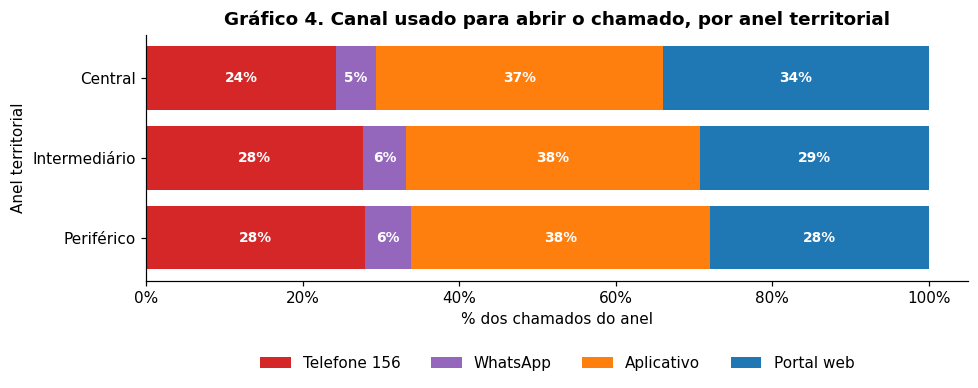

In [20]:
# Gráfico 4: canal por anel (barras empilhadas 100%)
pct = (pd.crosstab(canais['anel'], canais['Meio de Comunicação'], normalize='index') * 100).reindex(ORDEM_ANEL)
pct = pct[['CRM', 'CHATBOT', 'MOBILE', 'PORTAL']]
nomes = {'CRM': 'Telefone 156', 'CHATBOT': 'WhatsApp', 'MOBILE': 'Aplicativo', 'PORTAL': 'Portal web'}
cores_canal = ['#d62728', '#9467bd', '#ff7f0e', '#1f77b4']
fig, ax = plt.subplots(figsize=(9, 3.8))
esq = np.zeros(len(pct))
for c, cor in zip(pct.columns, cores_canal):
    ax.barh(pct.index, pct[c], left=esq, color=cor, label=nomes[c])
    for i, v in enumerate(pct[c]):
        if v > 4:
            ax.text(esq[i] + v / 2, i, f'{v:.0f}%', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    esq += pct[c].values
ax.set_title('Gráfico 4. Canal usado para abrir o chamado, por anel territorial')
ax.set_xlabel('% dos chamados do anel')
ax.set_ylabel('Anel territorial')
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.invert_yaxis()
ax.legend(ncol=4, bbox_to_anchor=(0.5, -0.25), loc='upper center', frameon=False)
plt.tight_layout(); plt.savefig('graficos/g4_canal_por_anel.png', bbox_inches='tight'); plt.show()

**Interpretação do Teste B e do Gráfico 4.** O p-valor é praticamente zero, então **rejeito H0**: o canal depende do território. O V de Cramér é pequeno, mas o padrão é consistente. Na periferia, a fatia do **telefone 156 e do WhatsApp é maior** e a do **portal web é menor** do que no centro. Isso sustenta a parte de canais da H3: uma solução que dependa só de site ou de aplicativo deixaria para trás justamente quem já chega menos à Prefeitura.

### 5.3 Correlação: distância do centro x chamados por habitante

**Por que escolhi.** Quero saber se a subnotificação cresce de forma **contínua** conforme a pessoa mora mais longe do centro, e não só comparar três grupos. Usei a **correlação de Spearman**, porque ela mede relações monotônicas, não exige normalidade e é robusta a subprefeituras atípicas. Cada ponto é uma subprefeitura (n = 32).

Spearman rho = -0.61 (p = 0.0002) | Pearson r = -0.64 (p = 0.0001)


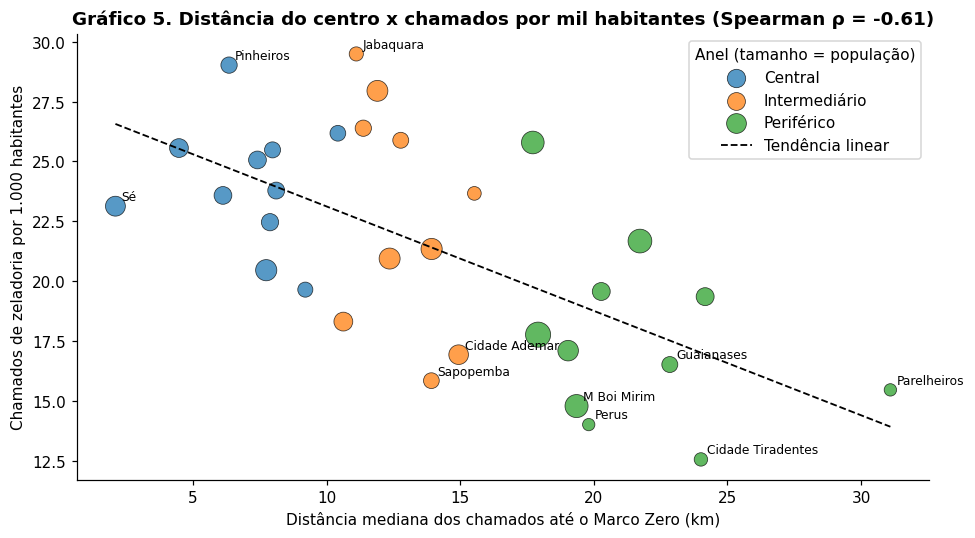

Cada 10 km a mais de distância: -4.4 chamados por mil habitantes (reta linear)


In [21]:
rho, p_rho = stats.spearmanr(ind['km_mediana'], ind['chamados_mil_hab'])
r_p, p_p = stats.pearsonr(ind['km_mediana'], ind['chamados_mil_hab'])
print(f'Spearman rho = {rho:.2f} (p = {p_rho:.4f}) | Pearson r = {r_p:.2f} (p = {p_p:.4f})')

# Gráfico 5: dispersão com reta de tendência
fig, ax = plt.subplots(figsize=(9, 5))
for a in ORDEM_ANEL:
    s = ind[ind.anel == a]
    ax.scatter(s.km_mediana, s.chamados_mil_hab, s=s.pop_2022 / 2500, color=CORES[a], alpha=.75,
               edgecolor='black', lw=.5, label=a)
coef = np.polyfit(ind.km_mediana, ind.chamados_mil_hab, 1)
xs = np.linspace(ind.km_mediana.min(), ind.km_mediana.max(), 50)
ax.plot(xs, np.polyval(coef, xs), ls='--', color='black', lw=1.2, label='Tendência linear')
for _, l in ind.iterrows():
    if l.chamados_mil_hab < 17 or l.chamados_mil_hab > 29 or l['sub'] == 'SE':
        ax.annotate(l.subprefeitura, (l.km_mediana, l.chamados_mil_hab), fontsize=8,
                    xytext=(4, 4), textcoords='offset points')
ax.set_title(f'Gráfico 5. Distância do centro x chamados por mil habitantes (Spearman ρ = {rho:.2f})')
ax.set_xlabel('Distância mediana dos chamados até o Marco Zero (km)')
ax.set_ylabel('Chamados de zeladoria por 1.000 habitantes')
ax.legend(title='Anel (tamanho = população)')
plt.tight_layout(); plt.savefig('graficos/g5_correlacao_distancia_demanda.png', bbox_inches='tight'); plt.show()
print(f'Cada 10 km a mais de distância: {coef[0]*10:.1f} chamados por mil habitantes (reta linear)')

**Interpretação.** A correlação é **negativa, moderada a forte e significativa** (p < 0,001). Quanto mais longe do centro, menos chamados por habitante. Pela reta de tendência, a cada 10 km de distância a taxa cai em alguns chamados por mil habitantes. Isso **sustenta a H2**.

Um cuidado importante: **correlação não é causalidade**. A distância não "causa" subnotificação. Ela resume um conjunto de fatores que costumam vir juntos na periferia, como menor acesso à internet, menor letramento digital, menos tempo livre e menor confiança de que o pedido será atendido. Esta análise não separa esses fatores; isso exigiria outras bases (renda, conectividade) e fica como próximo passo.

### 5.4 Probabilidade: chance de resolução em até 7 dias

**Por que escolhi.** Para o cidadão, "a mediana é 2 dias" é abstrato. A pergunta dele é: **"qual a chance de o meu problema ser resolvido em até uma semana?"** Estimo a probabilidade empírica P(T ≤ k) pela frequência relativa, para cada anel, e uma probabilidade condicional por serviço.

In [22]:
prob = pd.DataFrame({k: finalizados.groupby('anel')['dias_atendimento'].apply(lambda s: (s <= k).mean())
                     for k in [1, 7, 15, 30]}).reindex(ORDEM_ANEL)
prob.columns = [f'P(T ≤ {k} dias)' for k in prob.columns]
print((prob * 100).round(1).astype(str) + '%')

# Probabilidade condicional por serviço: P(T ≤ 7 | serviço)
p_serv = finalizados.groupby('servico')['dias_atendimento'].apply(lambda s: (s <= 7).mean()).sort_values()
print('\nP(resolvido em até 7 dias | serviço):')
print((p_serv * 100).round(1).astype(str).add('%').to_string())

              P(T ≤ 1 dias) P(T ≤ 7 dias) P(T ≤ 15 dias) P(T ≤ 30 dias)
anel                                                                   
Central               45.6%         73.0%          83.3%          92.9%
Intermediário         49.4%         73.0%          83.4%          94.1%
Periférico            48.9%         75.0%          85.6%          94.9%

P(resolvido em até 7 dias | serviço):
servico
Árvores                    31.9%
Fiação e postes            37.9%
Rios e córregos            51.4%
Asfalto e vias             60.0%
Drenagem                   67.8%
Calçadas e guias           70.2%
Capinação e roçada         72.4%
Praças                     82.7%
Grandes objetos            92.2%
Varrição e limpeza         93.7%
Entulho e ponto viciado    94.5%
Lixeiras públicas          94.6%


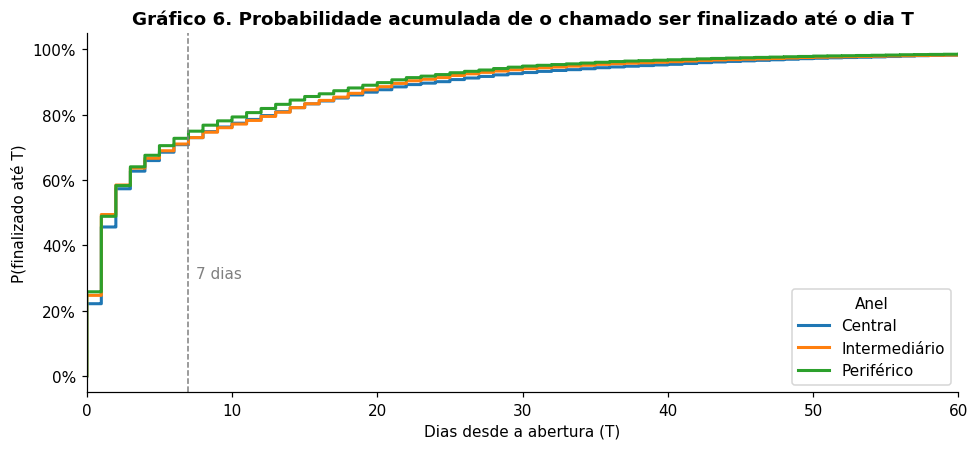

In [23]:
# Gráfico 6: curva de probabilidade acumulada (ECDF) por anel
fig, ax = plt.subplots(figsize=(9, 4.2))
for a in ORDEM_ANEL:
    s = np.sort(finalizados.loc[finalizados.anel == a, 'dias_atendimento'].values)
    ax.step(s, np.arange(1, len(s) + 1) / len(s), where='post', color=CORES[a], lw=2, label=a)
ax.axvline(7, ls='--', color='gray', lw=1)
ax.text(7.5, .3, '7 dias', color='gray')
ax.set_xlim(0, 60)
ax.set_title('Gráfico 6. Probabilidade acumulada de o chamado ser finalizado até o dia T')
ax.set_xlabel('Dias desde a abertura (T)')
ax.set_ylabel('P(finalizado até T)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(title='Anel')
plt.tight_layout(); plt.savefig('graficos/g6_probabilidade_acumulada.png', bbox_inches='tight'); plt.show()

**Interpretação.** Cerca de **3 em cada 4 chamados** finalizados são resolvidos em até 7 dias, com probabilidade **parecida nos três anéis** (as curvas quase se sobrepõem). A diferença grande aparece **entre serviços**: alguns são resolvidos quase sempre na primeira semana, outros raramente. Isso é útil para o UrbanIQ: o cidadão pode receber, no momento da abertura, uma **previsão realista** de prazo para o tipo de problema que relatou.

## 6. Visualizações

Os gráficos 1 a 6 foram apresentados junto com cada análise, e o Gráfico 7 (mapa) vem logo abaixo. Todos foram feitos com Matplotlib, com título, rótulos nos eixos, legenda e interpretação:

| Gráfico | Tipo | O que mostra |
|---|---|---|
| 1 | Linhas | Evolução mensal da demanda por anel |
| 2 | Pareto (barras + linha) | Concentração da demanda em poucos serviços |
| 3 | Boxplot | Distribuição do tempo de atendimento por anel |
| 4 | Barras empilhadas 100% | Canal de abertura por anel |
| 5 | Dispersão com tendência | Distância do centro x chamados por habitante |
| 6 | Curva acumulada (ECDF) | Probabilidade de resolução até o dia T |
| 7 | Mapa (densidade + bolhas) | Onde estão os pedidos e quais territórios pedem menos por habitante |

Todos foram salvos na pasta `graficos/` para uso no pitch e no painel.

### Gráfico 7: mapa da demanda

**Por que um mapa.** Os gráficos anteriores mostram a relação entre distância e demanda, mas um mapa deixa o padrão visível de imediato: **onde** estão os pedidos e **quais territórios** pedem menos por habitante. Não precisei de nenhum arquivo de contorno: as coordenadas dos próprios chamados desenham a cidade. O fundo cinza mostra a densidade de chamados (hexágonos, em escala logarítmica). Cada bolha é uma subprefeitura, posicionada na mediana das coordenadas dos seus chamados: a **cor** mostra os chamados por mil habitantes e o **tamanho** mostra a população.

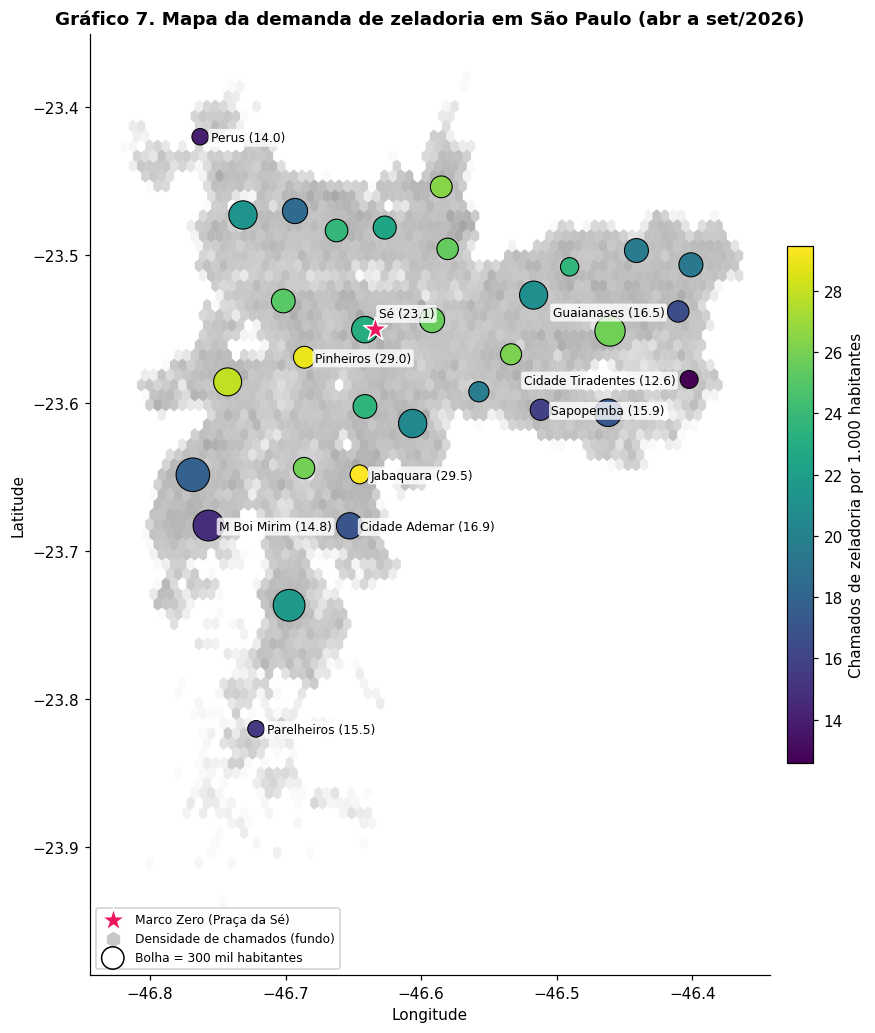

In [24]:
# Gráfico 7: mapa da demanda (densidade de chamados + bolhas por subprefeitura)
pts = z[['lat', 'lon']].dropna()
pts = pts[pts['lat'].between(-24.05, -23.35) & pts['lon'].between(-46.85, -46.35)]  # remove coordenadas fora do município
centro = z.groupby('sub')[['lat', 'lon']].median()
mapa = ind.set_index('sub').join(centro)

fig, ax = plt.subplots(figsize=(8.5, 9.5))
ax.hexbin(pts['lon'], pts['lat'], gridsize=75, bins='log', cmap='Greys', mincnt=1, alpha=.35, linewidths=0)
sc = ax.scatter(mapa['lon'], mapa['lat'], s=mapa['pop_2022'] / 1400, c=mapa['chamados_mil_hab'], cmap='viridis',
                edgecolor='black', linewidth=.7, zorder=3)
cb = fig.colorbar(sc, ax=ax, shrink=.55, pad=.02)
cb.set_label('Chamados de zeladoria por 1.000 habitantes')
for sub, l in mapa.iterrows():
    if l['chamados_mil_hab'] < 17 or l['chamados_mil_hab'] > 28.5 or sub == 'SE':
        leste = l['lon'] > -46.47
        ax.annotate(f"{l['subprefeitura']} ({l['chamados_mil_hab']:.1f})", (l['lon'], l['lat']), fontsize=8,
                    xytext=(-9, -3) if leste else ((9, 8) if sub == 'SE' else (7, -3)), textcoords='offset points',
                    ha='right' if leste else 'left', zorder=6,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=.8))
ax.scatter(-46.6339, -23.5503, marker='*', s=260, color='#ED185C', edgecolor='white', zorder=5, label='Marco Zero (Praça da Sé)')
ax.scatter([], [], s=80, color='#c8c8c8', marker='h', label='Densidade de chamados (fundo)')
ax.scatter([], [], s=300000 / 1400, facecolor='none', edgecolor='black', label='Bolha = 300 mil habitantes')
ax.set_aspect(1 / np.cos(np.radians(-23.6)))
ax.set_title('Gráfico 7. Mapa da demanda de zeladoria em São Paulo (abr a set/2026)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='lower left', fontsize=8, framealpha=.9)
plt.tight_layout(); plt.savefig('graficos/g7_mapa_demanda.png', bbox_inches='tight', dpi=150); plt.show()

**Interpretação do Gráfico 7.** O fundo cinza mostra que há chamados na cidade inteira, inclusive no extremo sul e no extremo leste: o serviço é usado em todo o território. Mas as bolhas das bordas (Cidade Tiradentes, Perus, M'Boi Mirim, Parelheiros, Guaianases) têm as cores mais escuras, ou seja, **menos pedidos por habitante**, enquanto as bolhas do centro e da zona oeste são mais claras. O mapa confirma visualmente a H2 e mostra **onde** o UrbanIQ deve começar: as subprefeituras periféricas com cor escura e bolha grande, que reúnem muita gente e pouca voz.

## 7. Conclusões e conexão com a solução

| Hipótese | Resultado | Evidência |
|---|---|---|
| **H1**: periferia espera mais | **Não sustentada** | Mann-Whitney unilateral não significativo; medianas iguais; P(T ≤ 7 dias) parecida nos três anéis |
| **H2**: periferia pede menos (subnotificação) | **Sustentada** | Spearman ρ ≈ −0,6 (p < 0,001); diferença de ~2,3x entre subprefeituras; anel periférico com taxa menor que o central |
| **H3**: canais não digitais e concentração de serviços | **Sustentada** (com efeito pequeno no canal) | Qui-quadrado significativo, mais telefone e WhatsApp na periferia; 3 serviços ≈ 2/3 da demanda |
| **Inconclusivo** | Causa da subnotificação | A distância resume vários fatores; os dados não permitem isolar renda, conectividade ou confiança |

**O principal achado mudou o foco do meu projeto.** Eu esperava provar que a Prefeitura atende pior a periferia. Os dados mostram outra coisa: **quando o chamado chega, ele é atendido em tempo parecido em toda a cidade. O problema é que da periferia chegam muito menos chamados por habitante.** A desigualdade está na **porta de entrada**, não no atendimento.

**Como isso ajusta o UrbanIQ:**

1. **Porta de entrada inclusiva.** O UrbanIQ precisa ser *omnichannel* desde o primeiro dia: WhatsApp com menu simples e áudio, telefone 156 integrado e registro presencial por agentes comunitários. O aplicativo é só mais um canal.
2. **Score de prioridade com equidade.** Proponho incluir na regra RN06 um componente de **equidade territorial**, baseado no `indice_subnotificacao` calculado aqui (0 = território que mais pede; 1 = que menos pede). Um chamado vindo de um território subnotificado ganha alguns pontos, porque cada pedido dali provavelmente representa vários problemas não relatados.
3. **Previsão de prazo por serviço.** Usar P(T ≤ k | serviço) para informar ao cidadão, na abertura, um prazo realista.
4. **Foco operacional.** Começar a calibração do score pelos 6 serviços que somam mais de 80% da demanda.

**Indicadores obtidos (linha de base para medir o impacto do UrbanIQ):**

In [25]:
kpis = {
    'Chamados de zeladoria por dia (cidade)': f'{len(z)/183:,.0f}',
    'Mediana do tempo de atendimento (dias)': f"{finalizados['dias_atendimento'].median():.0f}",
    'P(resolvido em até 7 dias)': f"{(finalizados['dias_atendimento'] <= 7).mean():.0%}",
    'Chamados por mil hab. no anel central (6 meses)': f"{comp.loc['Central','chamados_mil_hab']:.1f}",
    'Chamados por mil hab. no anel periférico (6 meses)': f"{comp.loc['Periférico','chamados_mil_hab']:.1f}",
    'Razão entre a maior e a menor taxa por subprefeitura': f'{mx.chamados_mil_hab/mn.chamados_mil_hab:.1f}x',
    '% de chamados por telefone/WhatsApp na periferia': f"{pct.loc['Periférico',['CRM','CHATBOT']].sum():.1f}%",
    'Reiterações do mesmo problema (6 meses)': f'{reiteracoes:,}',
}
pd.Series(kpis, name='Valor').to_frame()

,Valor
Chamados de zeladoria por dia (cidade),"1,340"
Mediana do tempo de atendimento (dias),2
P(resolvido em até 7 dias),74%
Chamados por mil hab. no anel central (6 meses),23.9
Chamados por mil hab. no anel periférico (6 meses),18.6
Razão entre a maior e a menor taxa por subprefeitura,2.3x
% de chamados por telefone/WhatsApp na periferia,33.8%
Reiterações do mesmo problema (6 meses),"11,245"


A meta de impacto do UrbanIQ seria **reduzir a diferença de chamados por habitante entre periferia e centro** sem piorar o tempo de atendimento, acompanhando esses indicadores mês a mês.

## 8. Limitações e uso responsável dos dados

**Limitações das bases e da análise**

- **Chamado não é igual a problema.** A própria Prefeitura alerta que o número de solicitações não corresponde ao número de problemas existentes. Uso essa limitação a meu favor (H2), mas não consigo medir os problemas reais que nunca viraram chamado.
- **Censura à direita.** A base foi extraída em 19/10/2026. Chamados abertos no fim de setembro tiveram pouco tempo para fechar, e cerca de 19% ainda estavam abertos. Ao calcular o tempo só com os finalizados, posso **subestimar** o tempo real. Combinei dois trimestres para reduzir esse efeito; uma análise de sobrevivência (Kaplan-Meier) seria o próximo passo.
- **Data sem hora.** O tempo é medido em dias inteiros; um chamado fechado no mesmo dia vale 0.
- **Período curto.** Seis meses não capturam efeitos de anos inteiros (por exemplo, a época de chuvas de verão para drenagem).
- **Reclassificação.** A Prefeitura pode reclassificar o serviço ou trocar o órgão de um chamado, então a categoria pode mudar entre publicações.
- **Critério de anel.** Os três anéis foram definidos por tercis de distância até o Marco Zero. É um critério objetivo e reproduzível, mas simplifica a realidade (há bolsões de vulnerabilidade em regiões centrais).
- **População de 2022.** Uso o Censo 2022 como denominador para dados de 2026.

**Vieses que podem excluir grupos**

- Um sistema que prioriza só pelo **volume de pedidos** favorece quem mais reclama, que é justamente quem tem mais acesso digital. Esse é o viés que a H2 encontrou, e o componente de equidade no score existe para corrigi-lo.
- Os dados não têm idade, deficiência ou renda do solicitante, então não consigo verificar se idosos ou pessoas com deficiência são sub-representados. No UrbanIQ, isso seria acompanhado com dados agregados e consentidos.

**Cuidados com a privacidade (LGPD)**

- A base pública já vem **anonimizada** pela Prefeitura (sem nome, CPF, telefone ou protocolo).
- Mesmo assim, endereço e coordenadas podem identificar uma residência. Por isso **trabalho e publico só agregados** (por subprefeitura e anel) e não exibo chamados individuais em mapas de alta precisão.
- No UrbanIQ: coleta mínima (finalidade e necessidade, art. 6º da LGPD), consentimento claro na abertura, pseudonimização do cidadão nas bases analíticas, controle de acesso por perfil e publicação no portal de transparência só com dados agregados.

In [26]:
print('Notebook executado do início ao fim. Arquivos gerados:')
import os
for pasta in ['dados', 'graficos']:
    for f in sorted(os.listdir(pasta)):
        if f.startswith(('tratados', 'g')):
            print(f'  {pasta}/{f}')

Notebook executado do início ao fim. Arquivos gerados:
  dados/tratados_chamados_zeladoria.csv
  dados/tratados_indicadores_subprefeitura.csv
  graficos/g1_evolucao_mensal.png
  graficos/g2_pareto_servicos.png
  graficos/g3_tempo_por_anel.png
  graficos/g4_canal_por_anel.png
  graficos/g5_correlacao_distancia_demanda.png
  graficos/g6_probabilidade_acumulada.png
  graficos/g7_mapa_demanda.png
